# Dataset C – COVID-19 Vaccine Uptake Hackathon
**Team:** _add names_  |  **Target:** `covid_vaccine` (1 = vaccinated, 0 = not vaccinated)

**Workflow:** 1) Setup → 2) EDA → 3) Metrics → 4) Split → 5) Pre-processing → 6) Model comparison → 7) Tuning → 8) Hold-out → 9) Submission

## 1. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.base import clone
try:
    from xgboost import XGBClassifier          # pre-installed on Colab; otherwise: !pip install xgboost
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed - XGBoost model will be skipped")
from sklearn.model_selection import cross_validate
from sklearn.metrics import (roc_auc_score, accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from scipy.stats import randint, uniform, loguniform

RANDOM_STATE = 42
sns.set_style("whitegrid")

# Colab: upload the CSV to the session (left sidebar -> Files) or mount Drive.
DATA_PATH = "dataset_C_training.csv"
df = pd.read_csv(DATA_PATH)
TARGET = "covid_vaccine"
print(df.shape)
df.head()

(4756, 31)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


## 2. Exploratory Data Analysis

In [2]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance               2848 non-null   f

,count,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,2378.500000,1373.083270,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,1.648609,0.903204,0.0,1.00,2.0,2.00,3.0
covid_knowledge,4729.0,1.296469,0.615705,0.0,1.00,1.0,2.00,2.0
behavioral_antiviral_meds,4742.0,0.053353,0.224760,0.0,0.00,0.0,0.00,1.0
behavioral_avoidance,4729.0,0.733347,0.442256,0.0,0.00,1.0,1.00,1.0
behavioral_face_mask,4754.0,0.072991,0.260149,0.0,0.00,0.0,0.00,1.0
behavioral_wash_hands,4747.0,0.839267,0.367323,0.0,1.00,1.0,1.00,1.0
behavioral_large_gatherings,4746.0,0.356300,0.478956,0.0,0.00,0.0,1.00,1.0
behavioral_outside_home,4742.0,0.329186,0.469967,0.0,0.00,0.0,1.00,1.0
behavioral_touch_face,4735.0,0.693981,0.460886,0.0,0.00,1.0,1.00,1.0


### 2.1 Target balance

covid_vaccine
0    0.673
1    0.327
Name: proportion, dtype: float64


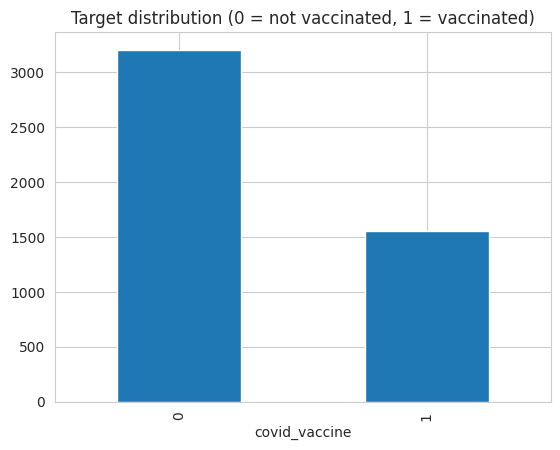

In [3]:
print(df[TARGET].value_counts(normalize=True).round(3))
df[TARGET].value_counts().plot(kind="bar", title="Target distribution (0 = not vaccinated, 1 = vaccinated)")
plt.show()

**Observation:** roughly one third of respondents are vaccinated, so the classes are imbalanced. Accuracy would be a misleading metric, and the costs below make that even more important.

### 2.2 Missing values

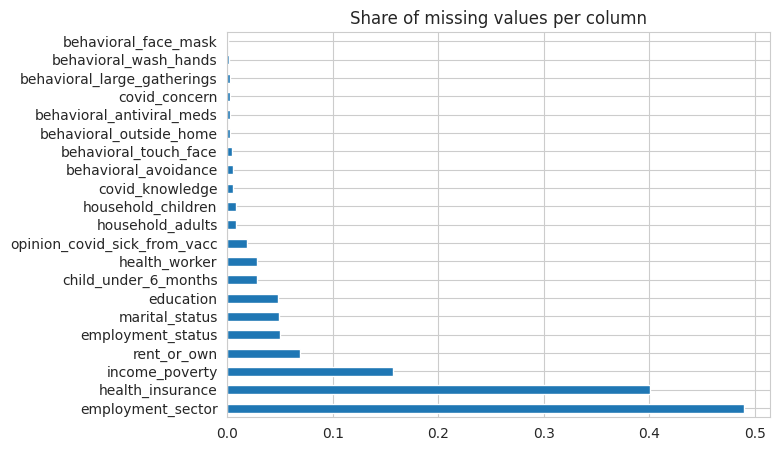

,0
employment_sector,0.490
health_insurance,0.401
income_poverty,0.157
rent_or_own,0.069
employment_status,0.050
marital_status,0.049
education,0.048
child_under_6_months,0.028
health_worker,0.028
opinion_covid_sick_from_vacc,0.019


In [4]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
miss.plot(kind="barh", figsize=(7, 5), title="Share of missing values per column")
plt.show()
miss.round(3)

**Observation:** `employment_sector` (~49%) and `health_insurance` (~40%) have a lot of missing values, and `income_poverty` ~16%. The missingness may itself be informative (e.g. not employed → no sector), so we keep a "Missing" category / missing indicator instead of dropping rows. Compare the target rate for missing vs. non-missing below.

In [5]:
for c in ["employment_sector", "health_insurance", "income_poverty"]:
    print(c)
    print(df.groupby(df[c].isna())[TARGET].mean().rename({False: "present", True: "missing"}).round(3), "\n")

employment_sector
employment_sector
present    0.326
missing    0.328
Name: covid_vaccine, dtype: float64 

health_insurance
health_insurance
present    0.430
missing    0.173
Name: covid_vaccine, dtype: float64 

income_poverty
income_poverty
present    0.333
missing    0.293
Name: covid_vaccine, dtype: float64 



### 2.3 Feature distributions

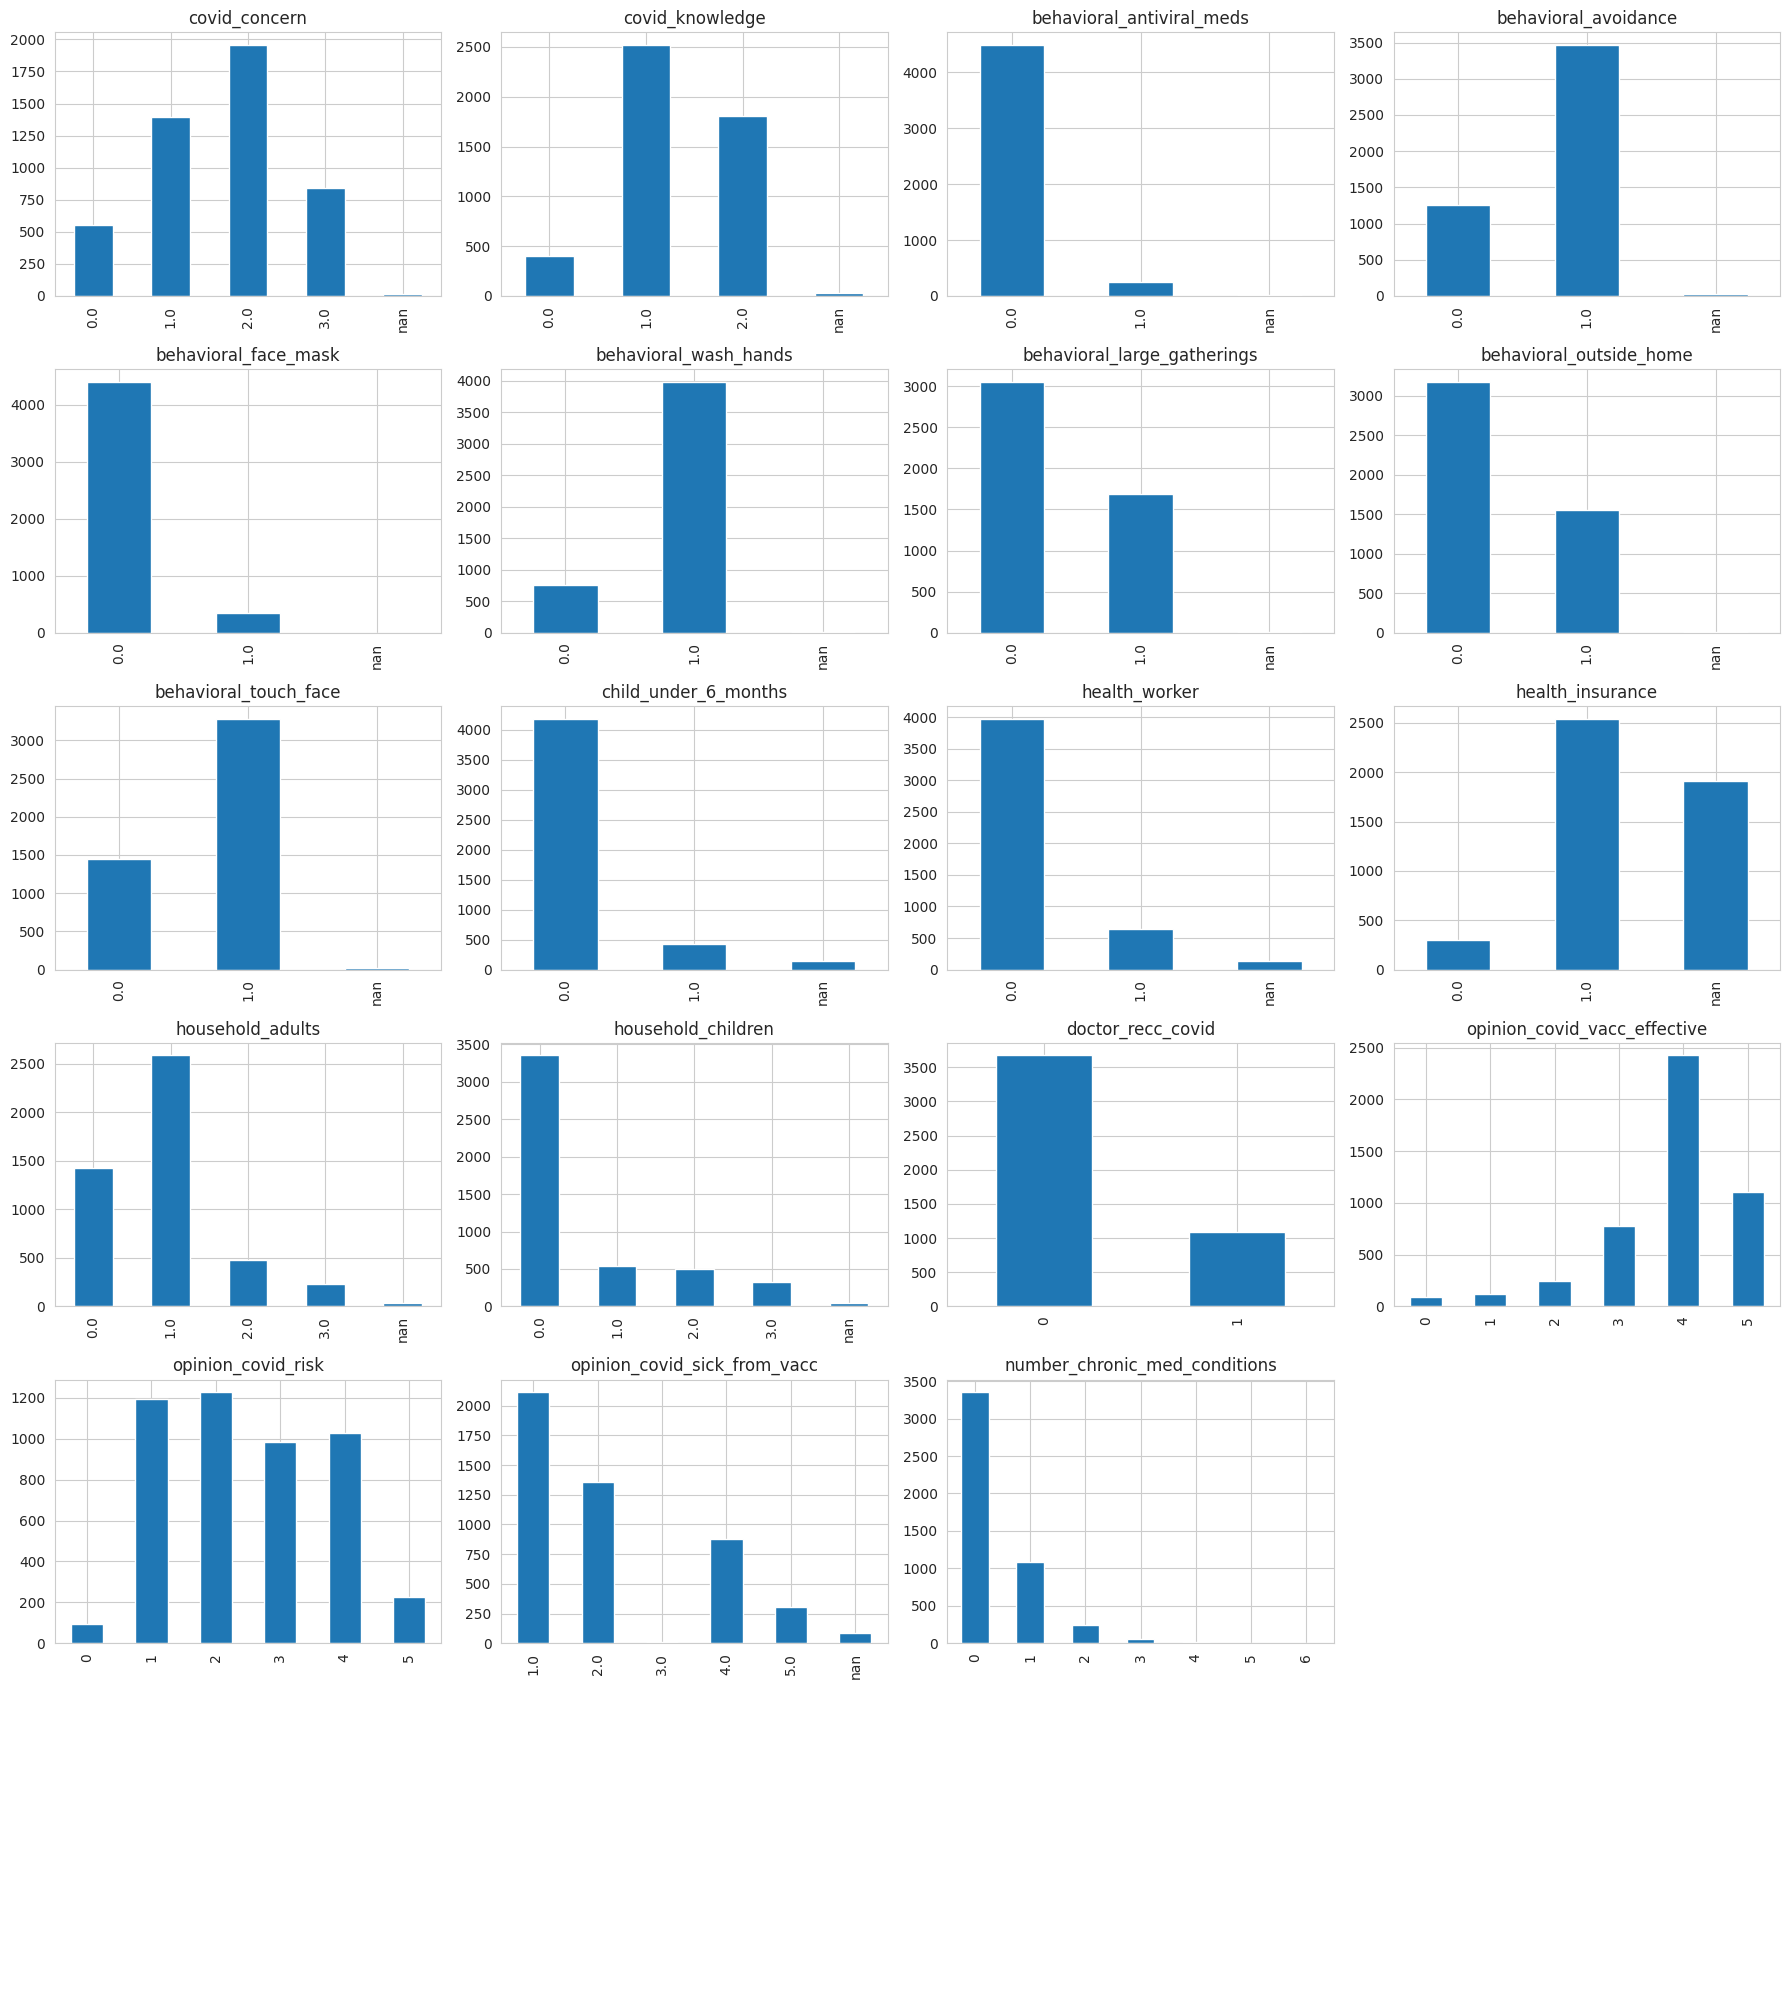

In [6]:
num_cols = df.select_dtypes("number").columns.drop(["respondent_id", TARGET]).tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

fig, axes = plt.subplots(6, 4, figsize=(18, 20))
for ax, c in zip(axes.ravel(), num_cols):
    df[c].value_counts(dropna=False).sort_index().plot(kind="bar", ax=ax, title=c)
    ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]: ax.axis("off")
plt.tight_layout(); plt.show()

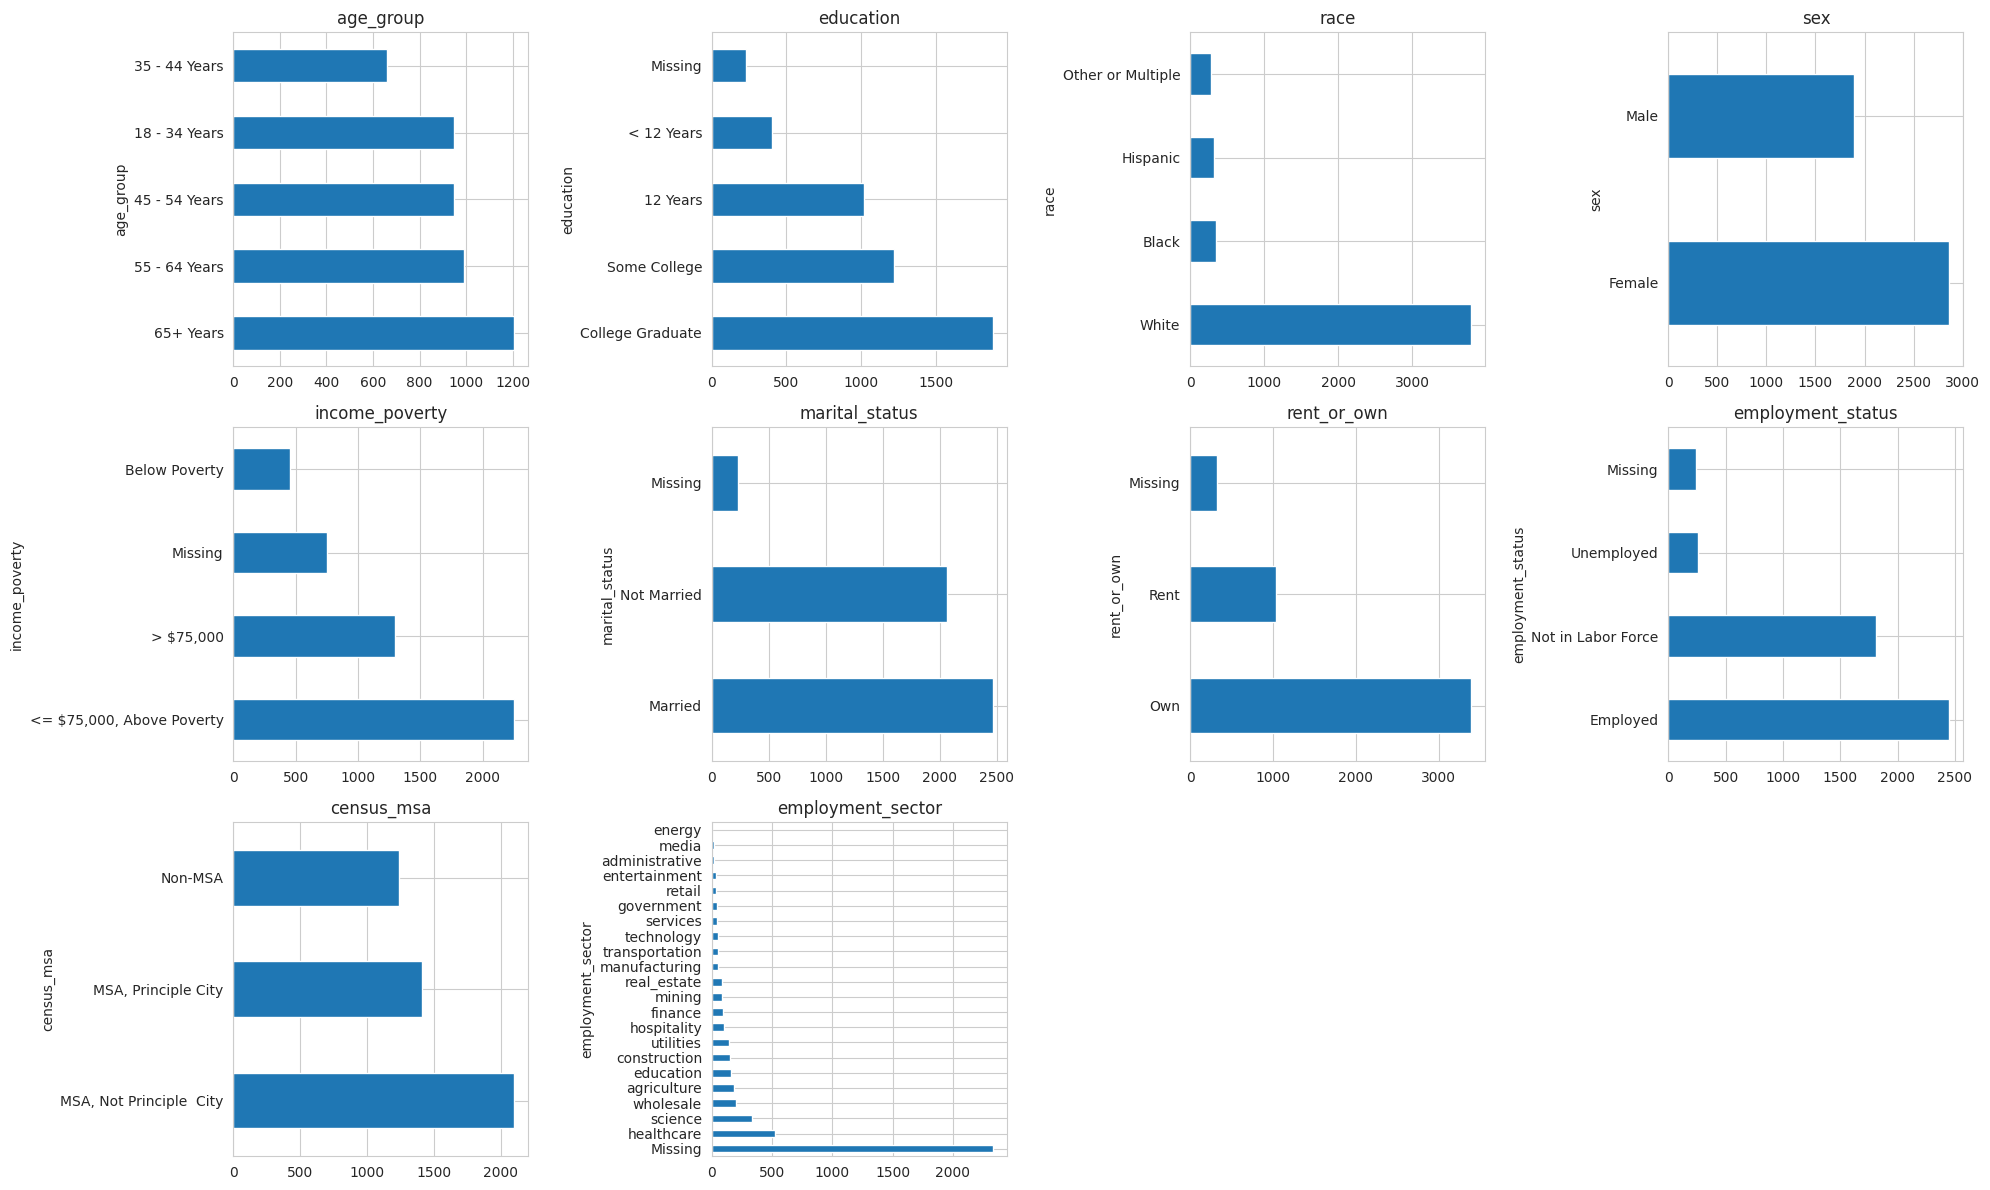

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, c in zip(axes.ravel(), cat_cols):
    df[c].fillna("Missing").value_counts().plot(kind="barh", ax=ax, title=c)
for ax in axes.ravel()[len(cat_cols):]: ax.axis("off")
plt.tight_layout(); plt.show()

### 2.4 Relationship with the target

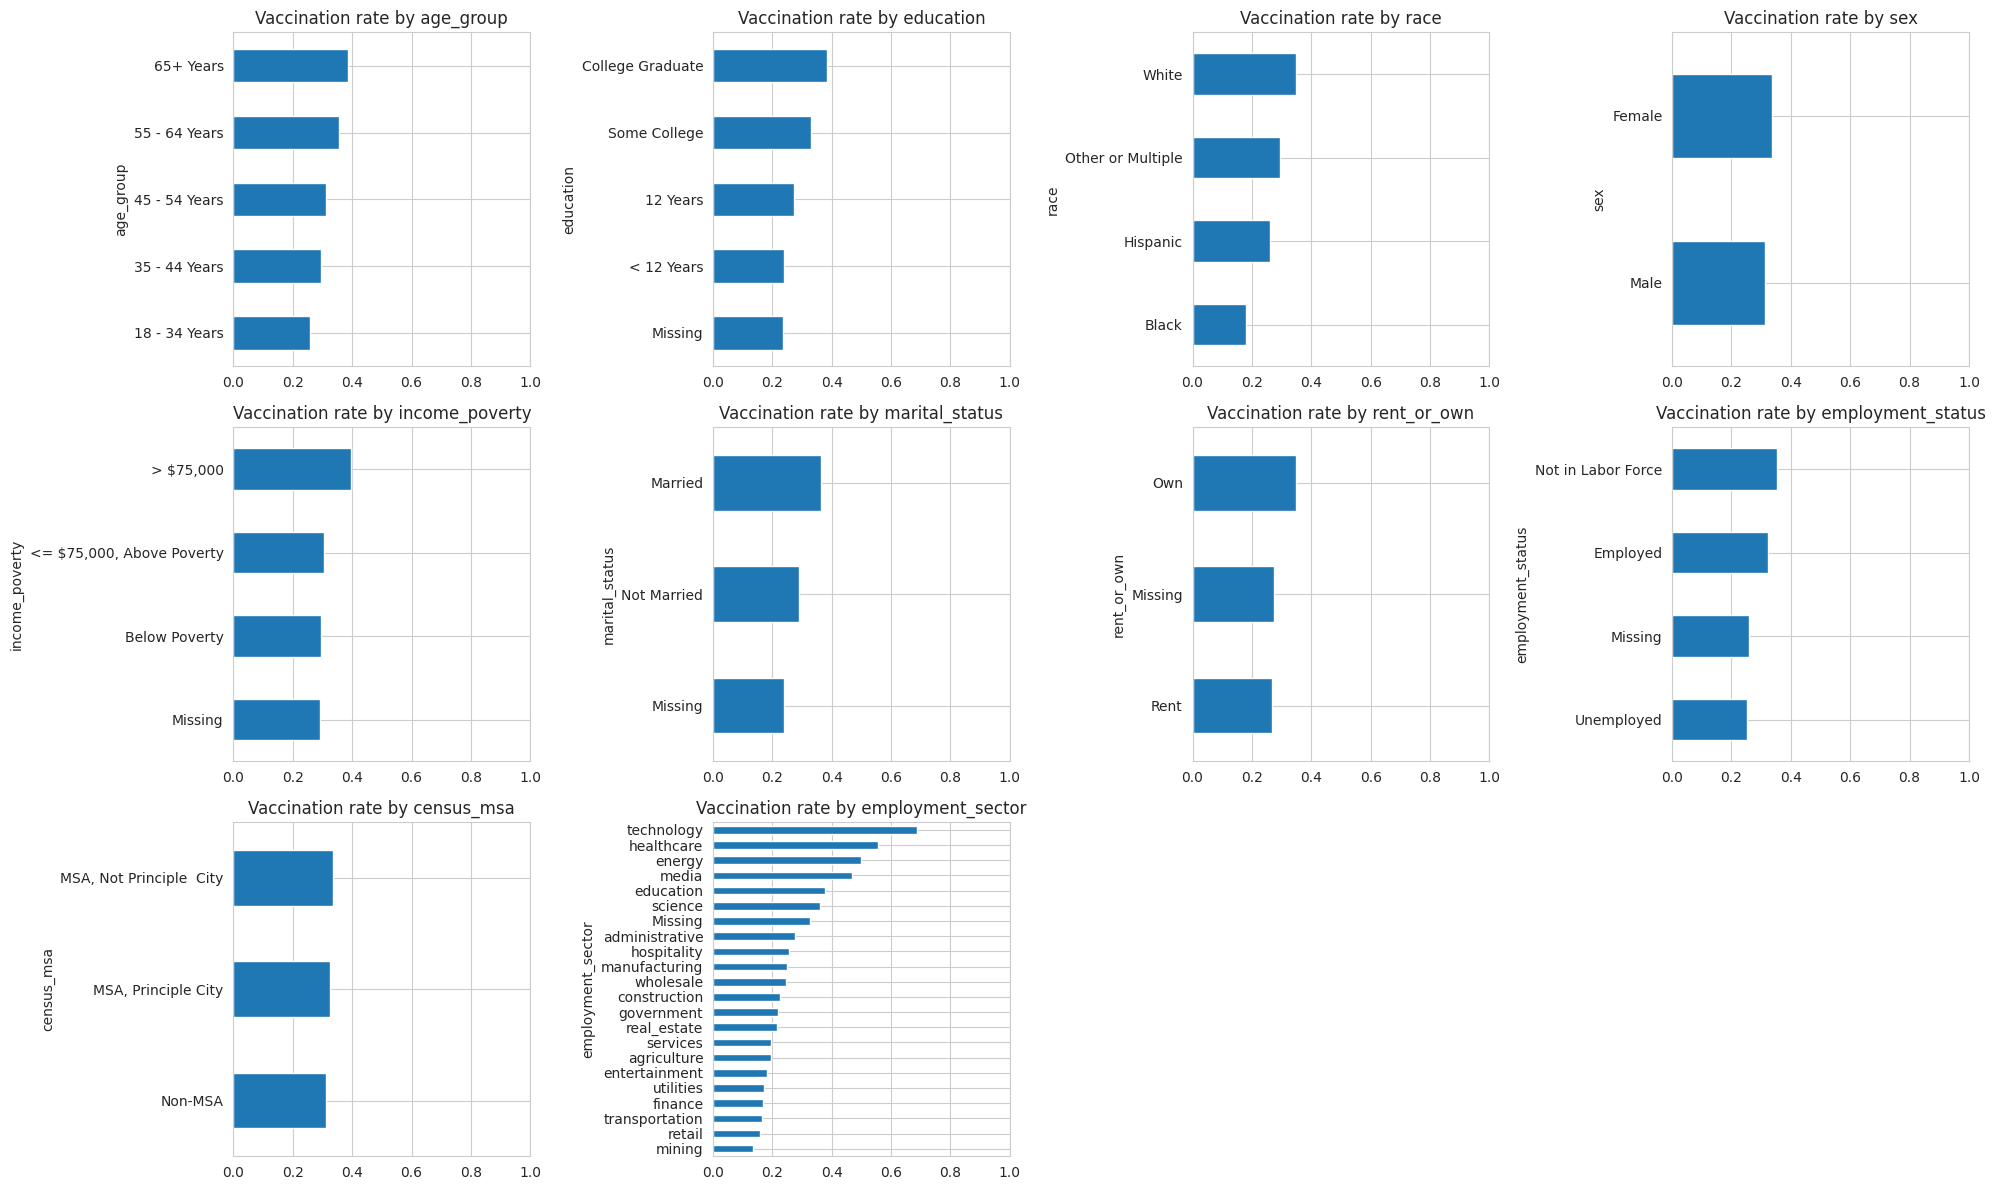

In [8]:
# Vaccination rate per category / value (top drivers)
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, c in zip(axes.ravel(), cat_cols):
    df.assign(**{c: df[c].fillna("Missing")}).groupby(c)[TARGET].mean().sort_values().plot(kind="barh", ax=ax, title=f"Vaccination rate by {c}")
    ax.set_xlim(0, 1)
for ax in axes.ravel()[len(cat_cols):]: ax.axis("off")
plt.tight_layout(); plt.show()

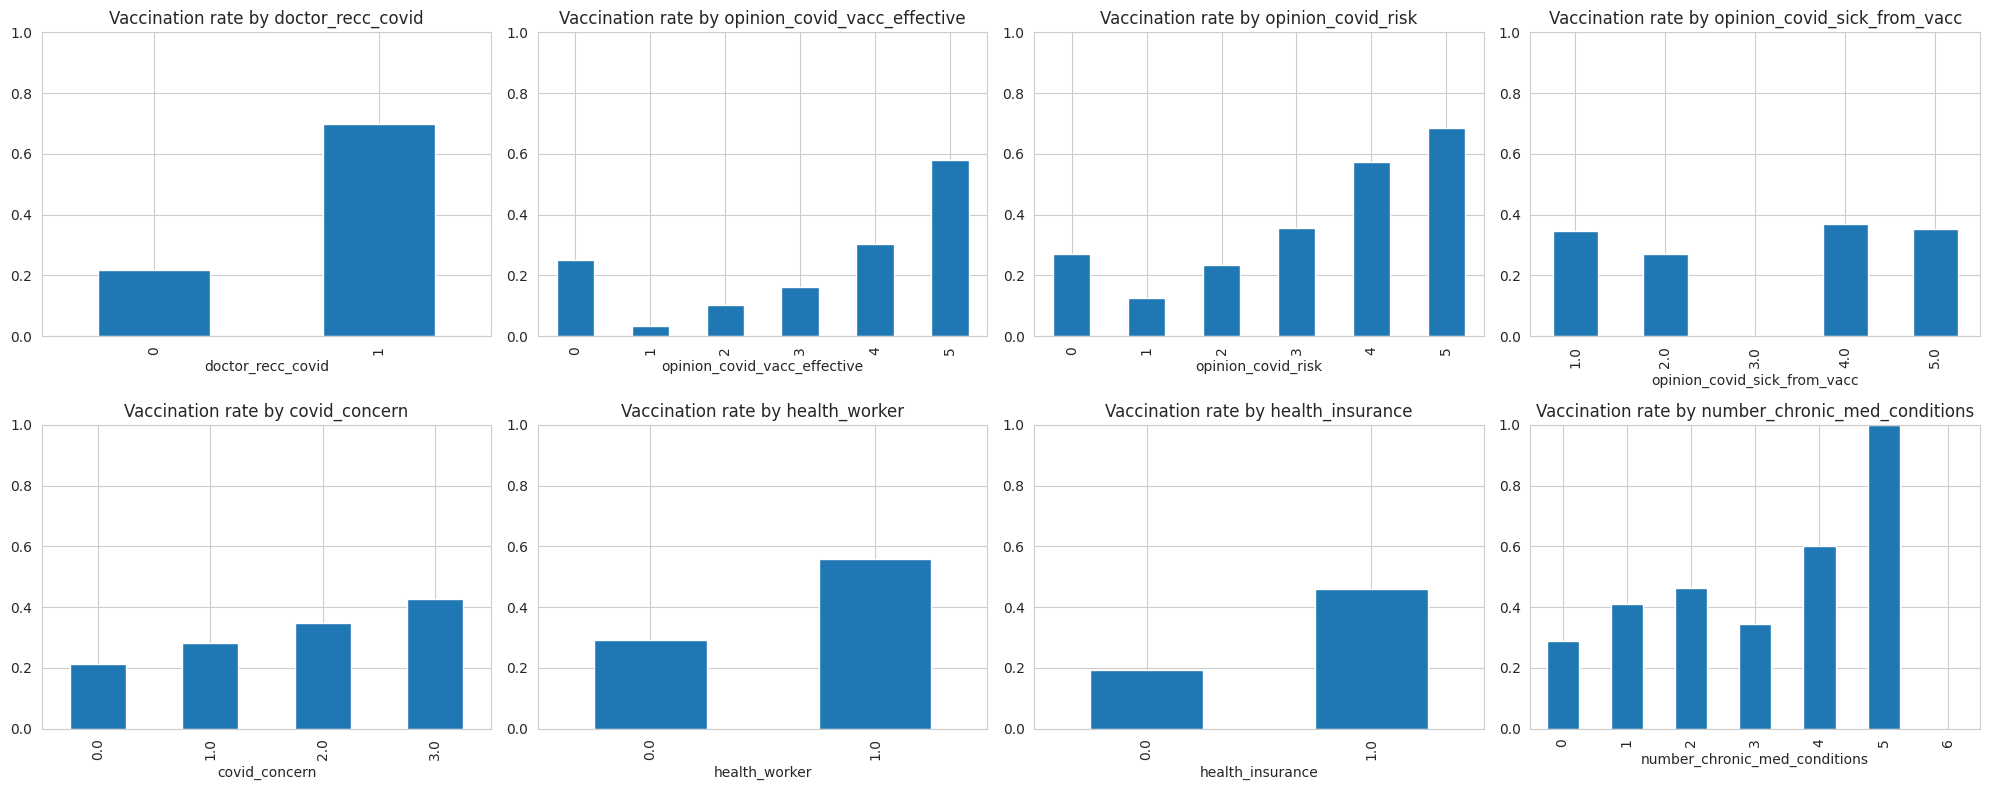

In [9]:
key = ["doctor_recc_covid", "opinion_covid_vacc_effective", "opinion_covid_risk",
       "opinion_covid_sick_from_vacc", "covid_concern", "health_worker", "health_insurance",
       "number_chronic_med_conditions"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), key):
    df.groupby(c)[TARGET].mean().plot(kind="bar", ax=ax, title=f"Vaccination rate by {c}")
    ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

### 2.5 Correlations

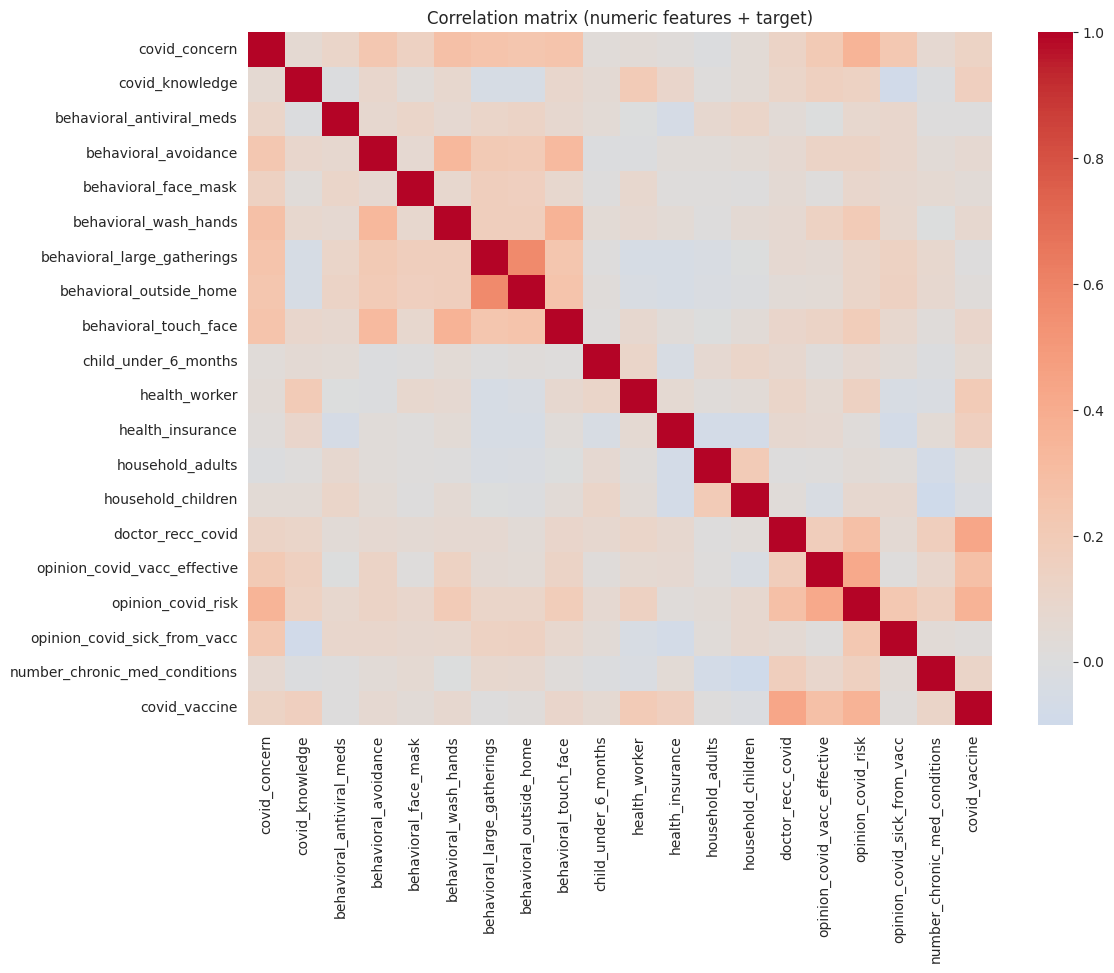

,covid_vaccine
doctor_recc_covid,0.430375
opinion_covid_risk,0.364942
opinion_covid_vacc_effective,0.277309
health_worker,0.197199
health_insurance,0.164584
covid_knowledge,0.164260
covid_concern,0.135191
number_chronic_med_conditions,0.114983
behavioral_touch_face,0.097420
behavioral_wash_hands,0.075328


In [10]:
corr = df[num_cols + [TARGET]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix (numeric features + target)")
plt.show()
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(10)

**EDA take-aways (edit after you've read the plots):**
- Doctor recommendation, belief in vaccine effectiveness, and perceived risk are expected to be among the strongest signals.
- Age group, health insurance and health-worker status also show clear differences in vaccination rate.
- Behavioural features are correlated with each other, which matters for linear models but not much for tree models.

## 3. Evaluation metrics
The classes are imbalanced (~33% vaccinated), so accuracy alone is misleading. We report:
- **ROC-AUC** (main metric for model selection and tuning – threshold-independent)
- **F1** (balance of precision and recall for the vaccinated class), **balanced accuracy**, precision, recall and accuracy

Baseline: always predicting "not vaccinated" gives ~67% accuracy but F1 = 0.

In [11]:
SCORING = {"roc_auc": "roc_auc", "f1": "f1", "balanced_acc": "balanced_accuracy",
           "precision": "precision", "recall": "recall", "accuracy": "accuracy"}
print("Majority-class baseline accuracy:", round(1 - df[TARGET].mean(), 3))

Majority-class baseline accuracy: 0.673


## 4. Train / hold-out split

In [12]:
X = df.drop(columns=[TARGET, "respondent_id"])   # id is random -> no information
y = df[TARGET]

X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_hold.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

(3804, 29) (952, 29)


## 5. Pre-processing
Two options are compared:
- **Option A:** median imputation (numeric), "Missing" category (categorical), one-hot encoding, scaling for linear models only.
- **Option B:** Option A + missing-value indicators for numeric columns (e.g. `health_insurance` has ~40% missing).

All steps are inside the pipeline, so they are fitted on training folds only (no leakage).

In [13]:
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

def make_preprocessor(add_indicator=False, scale=False):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=add_indicator))]
    if scale: num_steps.append(("sc", StandardScaler()))
    cat_steps = [("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                 ("oh", OneHotEncoder(handle_unknown="ignore"))]
    return ColumnTransformer([("num", Pipeline(num_steps), num_cols),
                              ("cat", Pipeline(cat_steps), cat_cols)])

def cv_report(name, pipe):
    """5-fold CV: mean and std of each metric."""
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    row = {"model": name}
    for k in SCORING:
        row[k] = s[f"test_{k}"].mean()
        row[k + "_std"] = s[f"test_{k}"].std()
    return row

## 6. Model comparison (default hyper-parameters, 5-fold CV)

In [14]:
candidates = {
 "LogReg (A)":       Pipeline([("pre", make_preprocessor(False, True)),  ("m", LogisticRegression(max_iter=2000))]),
 "LogReg (B)":       Pipeline([("pre", make_preprocessor(True,  True)),  ("m", LogisticRegression(max_iter=2000))]),
 "RandomForest (A)": Pipeline([("pre", make_preprocessor(False, False)), ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE))]),
 "RandomForest (B)": Pipeline([("pre", make_preprocessor(True,  False)), ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE))]),
 "HistGB (A)":       Pipeline([("pre", make_preprocessor(False, False)), ("m", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
 "HistGB (B)":       Pipeline([("pre", make_preprocessor(True,  False)), ("m", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
}
results = pd.DataFrame([cv_report(n, p) for n, p in candidates.items()]).sort_values("roc_auc", ascending=False).reset_index(drop=True)
results[["model", "roc_auc", "roc_auc_std", "f1", "f1_std", "balanced_acc", "precision", "recall", "accuracy"]].round(3)

,model,roc_auc,roc_auc_std,f1,f1_std,balanced_acc,precision,recall,accuracy
0,RandomForest (B),0.860,0.011,0.656,0.023,0.745,0.802,0.557,0.810
1,LogReg (B),0.859,0.009,0.689,0.013,0.767,0.765,0.629,0.815
2,HistGB (B),0.852,0.011,0.687,0.022,0.766,0.741,0.641,0.809
3,RandomForest (A),0.832,0.017,0.617,0.023,0.720,0.760,0.520,0.789
4,LogReg (A),0.827,0.013,0.642,0.014,0.735,0.735,0.571,0.792
5,HistGB (A),0.824,0.018,0.628,0.028,0.726,0.700,0.571,0.780


**Reading the table:** `*_std` is the spread across the 5 folds. If two models differ by less than that spread, treat them as equivalent. Compare option A vs B to say whether the missing indicators helped.

## 7. Hyper-parameter tuning (scored on ROC-AUC)

In [15]:
tune_spaces = {
 "LogReg": (Pipeline([("pre", make_preprocessor(True, True)), ("m", LogisticRegression(max_iter=3000))]),
            {"m__C": loguniform(1e-3, 1e2), "m__penalty": ["l1", "l2"], "m__solver": ["liblinear"]}),
 "RandomForest": (Pipeline([("pre", make_preprocessor(True, False)), ("m", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))]),
            {"m__n_estimators": randint(200, 600), "m__max_depth": [None, 6, 10, 16],
             "m__min_samples_leaf": randint(1, 20), "m__max_features": ["sqrt", 0.3, 0.5]}),
 "ExtraTrees": (Pipeline([("pre", make_preprocessor(True, False)), ("m", ExtraTreesClassifier(n_jobs=-1, random_state=RANDOM_STATE))]),
            {"m__n_estimators": randint(200, 600), "m__max_depth": [None, 8, 12, 20],
             "m__min_samples_leaf": randint(2, 25), "m__max_features": ["sqrt", 0.3, 0.5]}),
 "GradBoost": (Pipeline([("pre", make_preprocessor(True, False)), ("m", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
            {"m__n_estimators": randint(100, 400), "m__learning_rate": loguniform(0.01, 0.2),
             "m__max_depth": [2, 3, 4], "m__subsample": uniform(0.6, 0.4), "m__min_samples_leaf": randint(5, 40)}),
 "HistGB": (Pipeline([("pre", make_preprocessor(True, False)), ("m", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
            {"m__learning_rate": loguniform(0.01, 0.3), "m__max_iter": randint(100, 500),
             "m__max_depth": [None, 3, 5, 8], "m__min_samples_leaf": randint(10, 80),
             "m__l2_regularization": loguniform(1e-3, 10)}),
}
if HAS_XGB:
    tune_spaces["XGBoost"] = (
        Pipeline([("pre", make_preprocessor(True, False)),
                  ("m", XGBClassifier(tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE))]),
        {"m__n_estimators": randint(100, 500), "m__learning_rate": loguniform(0.01, 0.2),
         "m__max_depth": randint(2, 7), "m__subsample": uniform(0.6, 0.4),
         "m__colsample_bytree": uniform(0.5, 0.5), "m__min_child_weight": randint(1, 15),
         "m__reg_lambda": loguniform(0.1, 20)})

tuned = {}
for name, (pipe, space) in tune_spaces.items():
    search = RandomizedSearchCV(pipe, space, n_iter=20, scoring="roc_auc", cv=cv,
                                random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    print(f"{name:13s} best CV ROC-AUC = {search.best_score_:.4f}   params = {search.best_params_}")

# Ensembles of the tuned models (not fitted yet - they are fitted inside CV / before prediction)
all_base = [(n, clone(tuned[n])) for n in ["LogReg", "RandomForest", "ExtraTrees", "GradBoost", "HistGB", "XGBoost"] if n in tuned]
tuned["Voting"] = VotingClassifier(all_base, voting="soft", n_jobs=-1)                      # average of all probabilities
tuned["Stacking"] = StackingClassifier(all_base, final_estimator=LogisticRegression(max_iter=2000), cv=5, n_jobs=-1)  # meta-model on top
boost_base = [(n, clone(tuned[n])) for n in ["GradBoost", "HistGB", "XGBoost"] if n in tuned]
tuned["Voting (boosters)"] = VotingClassifier(boost_base, voting="soft", n_jobs=-1)         # boosting-only ensemble
print("Models in the final pool:", list(tuned))

LogReg        best CV ROC-AUC = 0.8607   params = {'m__C': np.float64(0.4206039057901998), 'm__penalty': 'l1', 'm__solver': 'liblinear'}
RandomForest  best CV ROC-AUC = 0.8596   params = {'m__max_depth': 16, 'm__max_features': 'sqrt', 'm__min_samples_leaf': 7, 'm__n_estimators': 321}
ExtraTrees    best CV ROC-AUC = 0.8597   params = {'m__max_depth': 8, 'm__max_features': 0.3, 'm__min_samples_leaf': 7, 'm__n_estimators': 585}
GradBoost     best CV ROC-AUC = 0.8626   params = {'m__learning_rate': np.float64(0.017398074711291726), 'm__max_depth': 4, 'm__min_samples_leaf': 22, 'm__n_estimators': 317, 'm__subsample': np.float64(0.7799016533479063)}
HistGB        best CV ROC-AUC = 0.8597   params = {'m__l2_regularization': np.float64(0.003077180271250686), 'm__learning_rate': np.float64(0.05388108577817234), 'm__max_depth': 5, 'm__max_iter': 134, 'm__min_samples_leaf': 45}
XGBoost       best CV ROC-AUC = 0.8647   params = {'m__colsample_bytree': np.float64(0.6558555380447055), 'm__learning_r

In [ ]:
tuned_results = pd.DataFrame([cv_report(f"{n} (tuned)", est) for n, est in tuned.items()]).sort_values("roc_auc", ascending=False).reset_index(drop=True)
tuned_results[["model", "roc_auc", "roc_auc_std", "f1", "f1_std", "balanced_acc", "precision", "recall", "accuracy"]].round(3)

## 8. Hold-out validation
The hold-out set was never used for tuning. Predictions use the default 0.5 threshold.

In [ ]:
hold_rows, hold_proba = [], {}
for name, est in tuned.items():
    est.fit(X_train, y_train)
    p = est.predict_proba(X_hold)[:, 1]; pred = (p >= 0.5).astype(int)
    hold_proba[name] = p
    hold_rows.append(dict(model=name, roc_auc=roc_auc_score(y_hold, p), f1=f1_score(y_hold, pred),
                          balanced_acc=balanced_accuracy_score(y_hold, pred),
                          precision=precision_score(y_hold, pred), recall=recall_score(y_hold, pred),
                          accuracy=accuracy_score(y_hold, pred)))
holdout = pd.DataFrame(hold_rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
holdout.round(3)

In [ ]:
# ROC curves + confusion matrix of the best model
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, p in hold_proba.items():
    RocCurveDisplay.from_predictions(y_hold, p, name=name, ax=ax[0])
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curves (hold-out)")
best = holdout.loc[0, "model"]
ConfusionMatrixDisplay.from_predictions(y_hold, (hold_proba[best] >= 0.5).astype(int), ax=ax[1], colorbar=False)
ax[1].set_title(f"Confusion matrix – {best}")
plt.show()
print(classification_report(y_hold, (hold_proba[best] >= 0.5).astype(int), target_names=["not vaccinated", "vaccinated"]))

In [ ]:
# Which features matter? (permutation importance on the best tree model, hold-out data)
from sklearn.inspection import permutation_importance
m = tuned["RandomForest"]
imp = permutation_importance(m, X_hold, y_hold, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(imp.importances_mean, index=X_hold.columns).sort_values().tail(12).plot(kind="barh", title="Permutation importance (ROC-AUC drop)")
plt.show()

**Critical evaluation (fill in):** compare CV vs hold-out scores (a big gap = over-fitting), mention the fold spread, say which pre-processing option helped, and justify the final ranking.

## 9. Cost of vaccination and hospitalisation
Costs from the information sheet: **vaccine = $1,500**, **hospitalisation = $41,000**.

We treat each prediction as a decision *(state this assumption in your report)*:
- Predicted **0 (not vaccinated)** → we vaccinate the person → **vaccination cost $1,500** (whether or not they would have been vaccinated anyway).
- Predicted **1 (vaccinated)** and actually **0** (false positive) → no intervention, the person is unprotected → **hospitalisation cost $41,000**.
- Predicted **1** and actually **1** → no cost.

`Total cost = 1,500 × (#predicted 0) + 41,000 × (#false positives)`

Because a false positive costs ~27x more than a vaccine, the cost-optimal rule is to predict 1 only when `P(vaccinated) > 41000 / (41000 + 1500)`... more precisely when `41000 × (1 − p) < 1500`, i.e. **p > 0.963**. So the 0.5 threshold is far from optimal for cost, and we choose the threshold on out-of-fold training predictions.

In [ ]:
COST_VACC, COST_HOSP = 1_500, 41_000

def cost_breakdown(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n_vaccinate = int((y_pred == 0).sum())                     # people we vaccinate
    n_hosp = int(((y_pred == 1) & (y_true == 0)).sum())        # unprotected people predicted as vaccinated
    vacc_cost, hosp_cost = n_vaccinate * COST_VACC, n_hosp * COST_HOSP
    return dict(n_vaccinated_by_us=n_vaccinate, n_hospitalised=n_hosp,
                vaccination_cost=vacc_cost, hospitalisation_cost=hosp_cost,
                total_cost=vacc_cost + hosp_cost, avg_cost_per_person=(vacc_cost + hosp_cost) / len(y_true))

THRESHOLDS = np.linspace(0.05, 0.99, 95)
def best_cost_threshold(y_true, proba):
    costs = [cost_breakdown(y_true, (proba >= t).astype(int))["total_cost"] for t in THRESHOLDS]
    return THRESHOLDS[int(np.argmin(costs))]

# Threshold per model chosen on out-of-fold TRAINING predictions (hold-out stays untouched)
cost_thr, oof_train = {}, {}
for name, est in tuned.items():
    oof_p = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_train[name] = oof_p
    cost_thr[name] = best_cost_threshold(y_train, oof_p)

rows = []
# reference strategies on the hold-out
rows.append(dict(strategy="Vaccinate everyone (predict all 0)", **cost_breakdown(y_hold, np.zeros(len(y_hold)))))
rows.append(dict(strategy="Vaccinate nobody (predict all 1)", **cost_breakdown(y_hold, np.ones(len(y_hold)))))
rows.append(dict(strategy="Perfect predictions", **cost_breakdown(y_hold, y_hold)))
for name in tuned:
    p = hold_proba[name]
    rows.append(dict(strategy=f"{name} @ 0.5", **cost_breakdown(y_hold, (p >= 0.5).astype(int))))
    rows.append(dict(strategy=f"{name} @ {cost_thr[name]:.2f} (cost-tuned)", **cost_breakdown(y_hold, (p >= cost_thr[name]).astype(int))))
cost_table = pd.DataFrame(rows).set_index("strategy")
cost_table.style.format("{:,.0f}", subset=cost_table.columns.drop("avg_cost_per_person")).format({"avg_cost_per_person": "{:,.1f}"})

In [ ]:
cost_table[["vaccination_cost", "hospitalisation_cost"]].plot(kind="barh", stacked=True, figsize=(10, 6),
        title="Hold-out cost breakdown by strategy ($)")
plt.tight_layout(); plt.show()

**Interpretation (fill in):** compare each model with the "vaccinate everyone" reference – a model is only worth using if its total cost is lower. Explain how much of the cost comes from vaccinations vs hospitalisations and why the cost-tuned threshold behaves differently from 0.5.

## 10. Choosing and ranking the best 5 models
Each model is scored two ways at its cost-tuned threshold: (1) **CV cost** on the training data (out-of-fold predictions) and (2) **hold-out cost** on the unseen 20%. The final ranking uses the **average of the two costs per person** (lower is better), with hold-out ROC-AUC as tie-breaker. Using both reduces the chance of picking a model that just got lucky on one split.

In [ ]:
rank_rows = []
for name in tuned:
    thr = cost_thr[name]
    cv_c = cost_breakdown(y_train, (oof_train[name] >= thr).astype(int))["avg_cost_per_person"]
    ho_c = cost_breakdown(y_hold, (hold_proba[name] >= thr).astype(int))["avg_cost_per_person"]
    rank_rows.append(dict(model=name, threshold=thr, cv_cost=cv_c, holdout_cost=ho_c, mean_cost=(cv_c + ho_c) / 2,
                          cv_auc=roc_auc_score(y_train, oof_train[name]), holdout_auc=roc_auc_score(y_hold, hold_proba[name])))
final_rank = (pd.DataFrame(rank_rows).sort_values(["mean_cost", "holdout_auc"], ascending=[True, False])
              .reset_index(drop=True))
final_rank.index += 1
final_rank.round(3)

**Justification (fill in):** explain why the top 5 were chosen – model families covered, CV vs hold-out agreement, size of the cost differences relative to noise. Note that ensembles usually give the most stable results.

## 11. Submission
Re-fit on **all** labelled data, predict the hidden test set, save one file per model ranked best to worst.
⚠️ Adjust file/column names to the format given with the test set.

In [ ]:
TEST_PATH = "dataset_C_testing.csv"                      # <- the test FEATURES file (same columns as training, no covid_vaccine)
EXAMPLE_PATH = "dataset_C_example_submission.csv"     # format reference: respondent_id, covid_vaccine

USE_COST_THRESHOLD = True   # True: predict 1 only above the cost-tuned threshold; False: plain 0.5

test = pd.read_csv(TEST_PATH)
example = pd.read_csv(EXAMPLE_PATH)
X_test = test.drop(columns=["respondent_id"], errors="ignore")[X.columns]

# sanity checks: same ids as the example submission
assert set(test["respondent_id"]) == set(example["respondent_id"]), "test ids differ from example submission"

for rank, row in final_rank.head(5).iterrows():   # top 5, best first (rank starts at 1)
    name = row["model"]
    est = tuned[name]
    est.fit(X, y)                                # re-fit on all labelled data
    thr = cost_thr[name] if USE_COST_THRESHOLD else 0.5
    pred = (est.predict_proba(X_test)[:, 1] >= thr).astype(float)   # 0.0 / 1.0, same as the example file
    sub = pd.DataFrame({"respondent_id": test["respondent_id"], TARGET: pred})
    sub = sub.set_index("respondent_id").loc[example["respondent_id"]].reset_index()   # same row order as example
    assert list(sub.columns) == list(example.columns) and len(sub) == len(example)
    sub.to_csv(f"prediction_{rank}_{name}.csv", index=False)
    print(rank, name, "-> share predicted vaccinated:", round(pred.mean(), 3))